# LAB 2 - Standardization and Normalization

Load the cleaned data from LAB 1, standardize and normalize it, concat everything
together, then compare one feature (**Glucose**) using two bar graphs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler

df_filled = pd.read_csv("LAB1_cleaned_data.csv")
df_filled.head()

,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [2]:
cols = [c for c in df_filled.columns if c != "Class"]

standardized = pd.DataFrame(
    StandardScaler().fit_transform(df_filled[cols]),
    columns=cols
)
print("Standardized data:")
standardized.head()

Standardized data:


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age
0,0.639947,0.865108,-0.033518,0.670643,-0.181541,0.166292,0.468492,1.425995
1,-0.844885,-1.206162,-0.529859,-0.012301,-0.181541,-0.852531,-0.365061,-0.190672
2,1.233880,2.015813,-0.695306,-0.012301,-0.181541,-1.332833,0.604397,-0.105584
3,-0.844885,-1.074652,-0.529859,-0.695245,-0.540642,-0.634212,-0.920763,-1.041549
4,-1.141852,0.503458,-2.680669,0.670643,0.316566,1.548980,5.484909,-0.020496


In [3]:
normalized = pd.DataFrame(
    MinMaxScaler().fit_transform(df_filled[cols]),
    columns=cols
)
print("Normalized data:")
normalized.head()

Normalized data:


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age
0,0.352941,0.670968,0.489796,0.304348,0.133413,0.314928,0.234415,0.483333
1,0.058824,0.264516,0.428571,0.239130,0.133413,0.171779,0.116567,0.166667
2,0.470588,0.896774,0.408163,0.239130,0.133413,0.104294,0.253629,0.183333
3,0.058824,0.290323,0.428571,0.173913,0.096154,0.202454,0.038002,0.000000
4,0.000000,0.600000,0.163265,0.304348,0.185096,0.509202,0.943638,0.200000


### Concat original, standardized and normalized data

In [4]:
standardized_out = standardized.add_suffix("_std")
normalized_out   = normalized.add_suffix("_norm")

processed = pd.concat([df_filled, standardized_out, normalized_out], axis=1)
processed.to_csv("LAB2_processed_data.csv", index=False)

print("Saved LAB2_processed_data.csv | shape:", processed.shape)
processed.head()

Saved LAB2_processed_data.csv | shape: (768, 25)


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class,Pregnant_std,...,Diabetes_Pedigree_std,Age_std,Pregnant_norm,Glucose_norm,Diastolic_BP_norm,Skin_Fold_norm,Serum_Insulin_norm,BMI_norm,Diabetes_Pedigree_norm,Age_norm
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1,0.639947,...,0.468492,1.425995,0.352941,0.670968,0.489796,0.304348,0.133413,0.314928,0.234415,0.483333
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0,-0.844885,...,-0.365061,-0.190672,0.058824,0.264516,0.428571,0.239130,0.133413,0.171779,0.116567,0.166667
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1,1.233880,...,0.604397,-0.105584,0.470588,0.896774,0.408163,0.239130,0.133413,0.104294,0.253629,0.183333
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,-0.844885,...,-0.920763,-1.041549,0.058824,0.290323,0.428571,0.173913,0.096154,0.202454,0.038002,0.000000
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,-1.141852,...,5.484909,-0.020496,0.000000,0.600000,0.163265,0.304348,0.185096,0.509202,0.943638,0.200000


### Bar graph 1: Glucose (original) vs Glucose_norm

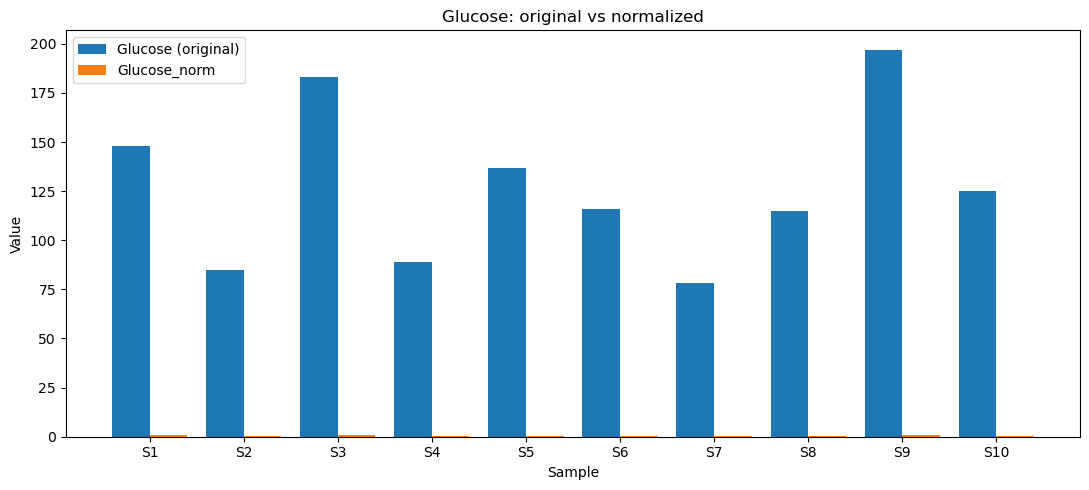

In [5]:
n = 10
x = np.arange(n)
width = 0.4

plt.figure(figsize=(11, 5))
plt.bar(x - width/2, processed["Glucose"].head(n),      width, label="Glucose (original)")
plt.bar(x + width/2, processed["Glucose_norm"].head(n), width, label="Glucose_norm")
plt.xticks(x, [f"S{i+1}" for i in range(n)])
plt.xlabel("Sample")
plt.ylabel("Value")
plt.title("Glucose: original vs normalized")
plt.legend()
plt.tight_layout()
plt.show()

### Bar graph 2: Glucose (original) vs Glucose_std

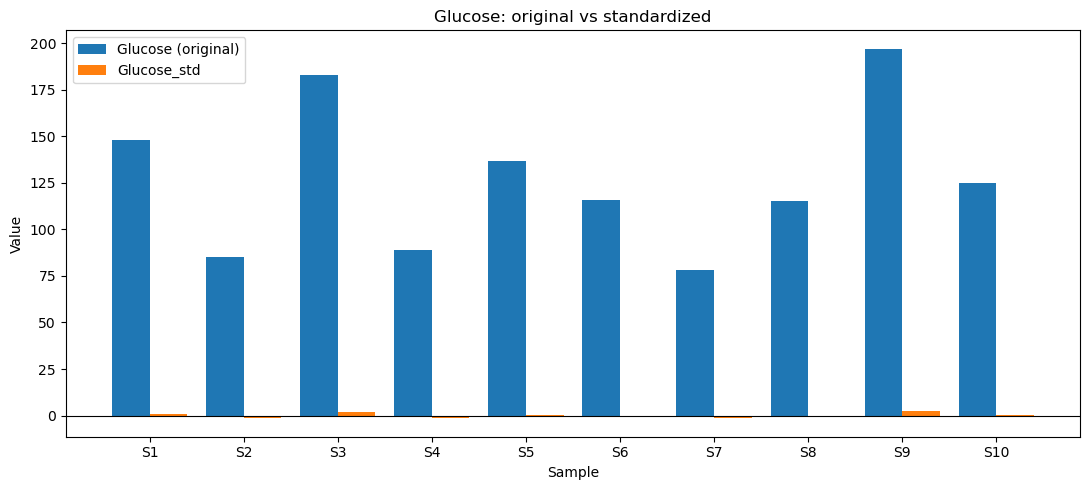

In [6]:
plt.figure(figsize=(11, 5))
plt.bar(x - width/2, processed["Glucose"].head(n),     width, label="Glucose (original)")
plt.bar(x + width/2, processed["Glucose_std"].head(n), width, label="Glucose_std")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(x, [f"S{i+1}" for i in range(n)])
plt.xlabel("Sample")
plt.ylabel("Value")
plt.title("Glucose: original vs standardized")
plt.legend()
plt.tight_layout()
plt.show()